# Rehab gesture recognition on IntelliRehabDS (Kinect skeleton data)

**Goal:** given one repetition of a rehab exercise (a few seconds of Kinect body-joint positions), recognise **which of 9 gestures** it is.

**Dataset:** IntelliRehabDS (IRDS), Zenodo record 4610859, CC BY 4.0. 29 people (15 rehab patients, 14 healthy) x 9 gestures x several repetitions.
One file = one repetition. Each row of a file = one camera frame, with 25 joints x (x, y, z) = 75 numbers.

**Pipeline:** load from Google Drive -> EDA -> clean and turn each repetition into features -> mirror augmentation -> 4 models + ensemble -> results and plots.

**Before you run:** Runtime -> Change runtime type -> **T4 GPU**, then Runtime -> Run all. The first run downloads about 200 MB into your Drive once; later runs find it there.

## 1. Imports, Google Drive and settings

In [ ]:
import re, urllib.request, zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn
from sklearn.model_selection import GroupKFold, LeaveOneGroupOut
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, balanced_accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from google.colab import drive
drive.mount("/content/drive")

DRIVE_DIR = Path("/content/drive/MyDrive/IRDS_data")   # permanent copy: the zip lives here
ROOT = Path("/content/IRDS")                           # fast local copy, rebuilt from the zip when missing
URL = "https://zenodo.org/records/4610859/files/SkeletonData.zip?download=1"
ZIP = DRIVE_DIR / "SkeletonData.zip"

FOLDER = "simplified"          # use files whose path contains this word ("" = all). The zip has Raw and Simplified copies.
EXCLUDE_SUBJECTS = ["217"]     # stopped mid-recording; the dataset paper excludes this subject
N_FRAMES = 100                 # every repetition is resampled to this many frames
N_FOLDS = 5                    # people-separated folds. None = leave-one-subject-out (strictest, but slow for the CNN)
N_SEEDS = 3                    # CNN is trained this many times and averaged

GESTURES = ["Elbow flex L", "Elbow flex R", "Shoulder flex L", "Shoulder flex R", "Shoulder abd L",
            "Shoulder abd R", "Shoulder fwd elev", "Side tap L", "Side tap R"]
JOINTS = ["SpineBase", "SpineMid", "Neck", "Head", "ShoulderLeft", "ElbowLeft", "WristLeft", "HandLeft",
          "ShoulderRight", "ElbowRight", "WristRight", "HandRight", "HipLeft", "KneeLeft", "AnkleLeft", "FootLeft",
          "HipRight", "KneeRight", "AnkleRight", "FootRight", "SpineShoulder", "HandTipLeft", "ThumbLeft",
          "HandTipRight", "ThumbRight"]
names = [f"{j}_{a}" for j in JOINTS for a in "xyz"]

def has_data():
    return ROOT.exists() and any(ROOT.rglob("*.txt"))

if not has_data():
    DRIVE_DIR.mkdir(parents=True, exist_ok=True)
    if zipfile.is_zipfile(ZIP):
        print("Found in Drive, unzipping ...")
    else:
        print("Not in Drive, downloading once (~200 MB) ...")
        urllib.request.urlretrieve(URL, ZIP.with_suffix(".part"))
        ZIP.with_suffix(".part").rename(ZIP)           # only becomes the real file once fully downloaded
    ROOT.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(ZIP) as z:
        z.extractall(ROOT)
print("Data found:", has_data())

Mounted at /content/drive
Found in Drive, unzipping ...
Data found: True


## 2. Find the repetitions

The label information is in the **file name**: `SubjectID_DateID_Gesture_Repetition_CorrectLabel_Position.txt`.
For example `216_18_2_5_2_stand.txt` = subject 216 (a patient), gesture 2, repetition 5, label 2 (incorrect), standing.
Subjects whose ID starts with 2 are patients; 1xx and 3xx are healthy. macOS junk files (`._...`) do not match the pattern and are skipped.

In [ ]:
NAME_RE = re.compile(r"^(\d+)_(\d+)_(\d)_(\d+)_(\d)_(.+)\.txt$")
rows = []
for p in ROOT.rglob("*.txt"):
    m = NAME_RE.match(p.name)
    if m:
        rows.append(dict(path=p, subject=m[1], gesture=int(m[3]), rep=int(m[4]),
                         incorrect=int(m[5]) == 2, position=m[6].lower()))
meta = pd.DataFrame(rows)
if FOLDER:
    meta = meta[meta.path.map(lambda p: FOLDER in str(p).lower())]
assert len(meta), "No files found: check ROOT and FOLDER."
meta = meta[~meta.subject.isin(EXCLUDE_SUBJECTS)].reset_index(drop=True)
meta["patient"] = meta.subject.str.startswith("2")
print("Repetitions:", len(meta), "| people:", meta.subject.nunique(),
      "| patients:", meta[meta.patient].subject.nunique(), "| healthy:", meta[~meta.patient].subject.nunique())
meta.drop(columns="path").head()

Repetitions: 2528 | people: 29 | patients: 15 | healthy: 14


,subject,gesture,rep,incorrect,position,patient
0,216,2,5,True,stand,True
1,305,6,1,False,chair,False
2,215,2,8,False,stand,True
3,104,0,4,False,stand,False
4,211,2,1,True,stand,True


## 3. Load the time series

Each file becomes a table: rows = frames, 75 columns = 25 joints x (x, y, z), in metres.
x = left/right, y = up, z = distance from the camera (about 2 m).

In [ ]:
def load_series(path):
    df = pd.read_csv(path, sep=None, engine="python", header=None)
    df = df.apply(pd.to_numeric, errors="coerce").dropna(axis=1, how="all").dropna(axis=0, how="all")
    return df.ffill().bfill().to_numpy(dtype=float)

series = [load_series(p) for p in meta.path]
keep = np.array([s.shape[1] == 75 for s in series])
print(f"Dropping {(~keep).sum()} files that do not have 75 columns.")
meta = meta[keep].reset_index(drop=True)
series = [s for s, k in zip(series, keep) if k]
meta["length"] = [len(s) for s in series]

print("\nOne file:", meta.path[0].name, "->", series[0].shape, "(frames, columns)")
print(pd.DataFrame(series[0][:5, :6], columns=names[:6]).round(3))
print("\nFrames per repetition:")
print(meta.length.describe().round(1))

Dropping 0 files that do not have 75 columns.

One file: 216_18_2_5_2_stand.txt -> (114, 75) (frames, columns)
   SpineBase_x  SpineBase_y  SpineBase_z  SpineMid_x  SpineMid_y  SpineMid_z
0       -0.003       -0.099        2.022       0.006        0.21       2.015
1       -0.003       -0.099        2.022       0.006        0.21       2.016
2       -0.003       -0.099        2.023       0.006        0.21       2.016
3       -0.003       -0.099        2.023       0.006        0.21       2.016
4       -0.003       -0.099        2.023       0.006        0.21       2.016

Frames per repetition:
count    2528.0
mean       88.3
std       137.6
min        13.0
25%        50.0
50%        63.0
75%        89.0
max      4736.0
Name: length, dtype: float64


## 4. EDA: what is in the data?

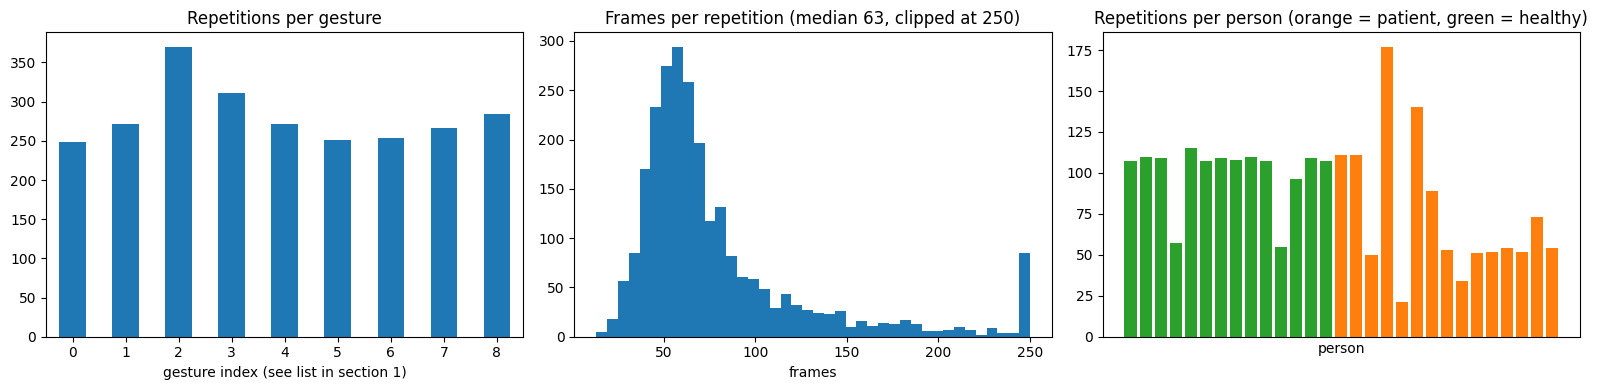

position
chair           844
sit             110
stand          1222
stand-frame      52
wheelchair      300
Name: reps, dtype: int64


In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
meta.gesture.value_counts().sort_index().plot.bar(ax=ax[0], rot=0, color="tab:blue")
ax[0].set_title("Repetitions per gesture"); ax[0].set_xlabel("gesture index (see list in section 1)")

ax[1].hist(meta.length.clip(upper=250), bins=40, color="tab:blue")
ax[1].set_title(f"Frames per repetition (median {int(meta.length.median())}, clipped at 250)"); ax[1].set_xlabel("frames")

per = meta.groupby(["subject", "patient"]).size().reset_index(name="reps").sort_values(["patient", "subject"])
ax[2].bar(range(len(per)), per.reps, color=np.where(per.patient, "tab:orange", "tab:green"))
ax[2].set_title("Repetitions per person (orange = patient, green = healthy)"); ax[2].set_xlabel("person"); ax[2].set_xticks([])
plt.tight_layout(); plt.savefig("eda_overview.png", dpi=150); plt.show()

print(meta.groupby("position").size().rename("reps"))

### What does the skeleton look like?

One repetition, drawn as a stick figure at four moments in time (front view: x across, y up). Left-side arm joints are red, right-side blue.

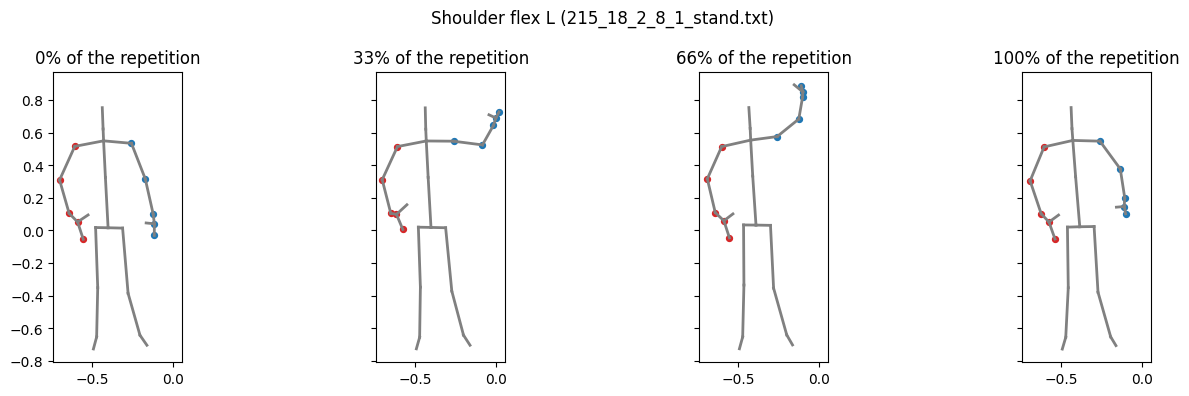

In [ ]:
BONES = [(0,1),(1,20),(20,2),(2,3),(20,4),(4,5),(5,6),(6,7),(7,21),(7,22),(20,8),(8,9),(9,10),(10,11),(11,23),(11,24),
         (0,12),(12,13),(13,14),(14,15),(0,16),(16,17),(17,18),(18,19)]
i = int(meta[(meta.gesture == 2) & meta.patient & ~meta.incorrect].index[0])
x = series[i].reshape(len(series[i]), 25, 3)
fig, ax = plt.subplots(1, 4, figsize=(14, 4), sharex=True, sharey=True)
for a, f in zip(ax, [0, 0.33, 0.66, 1.0]):
    J = x[int(f * (len(x) - 1))]
    for p, q in BONES:
        a.plot(*zip(J[p, :2], J[q, :2]), color="gray", lw=2)
    a.scatter(J[[4,5,6,7,21], 0], J[[4,5,6,7,21], 1], color="tab:red", s=18)
    a.scatter(J[[8,9,10,11,23], 0], J[[8,9,10,11,23], 1], color="tab:blue", s=18)
    a.set_title(f"{int(f * 100)}% of the repetition"); a.set_aspect("equal")
fig.suptitle(f"{GESTURES[meta.gesture[i]]} ({meta.path[i].name})")
plt.tight_layout(); plt.savefig("skeleton_frames.png", dpi=150); plt.show()

### The signal of each gesture

For every gesture: all its repetitions (resampled to the same length), for the one coordinate that moves the most.
If the 9 plots look different from each other, the classification task is learnable.

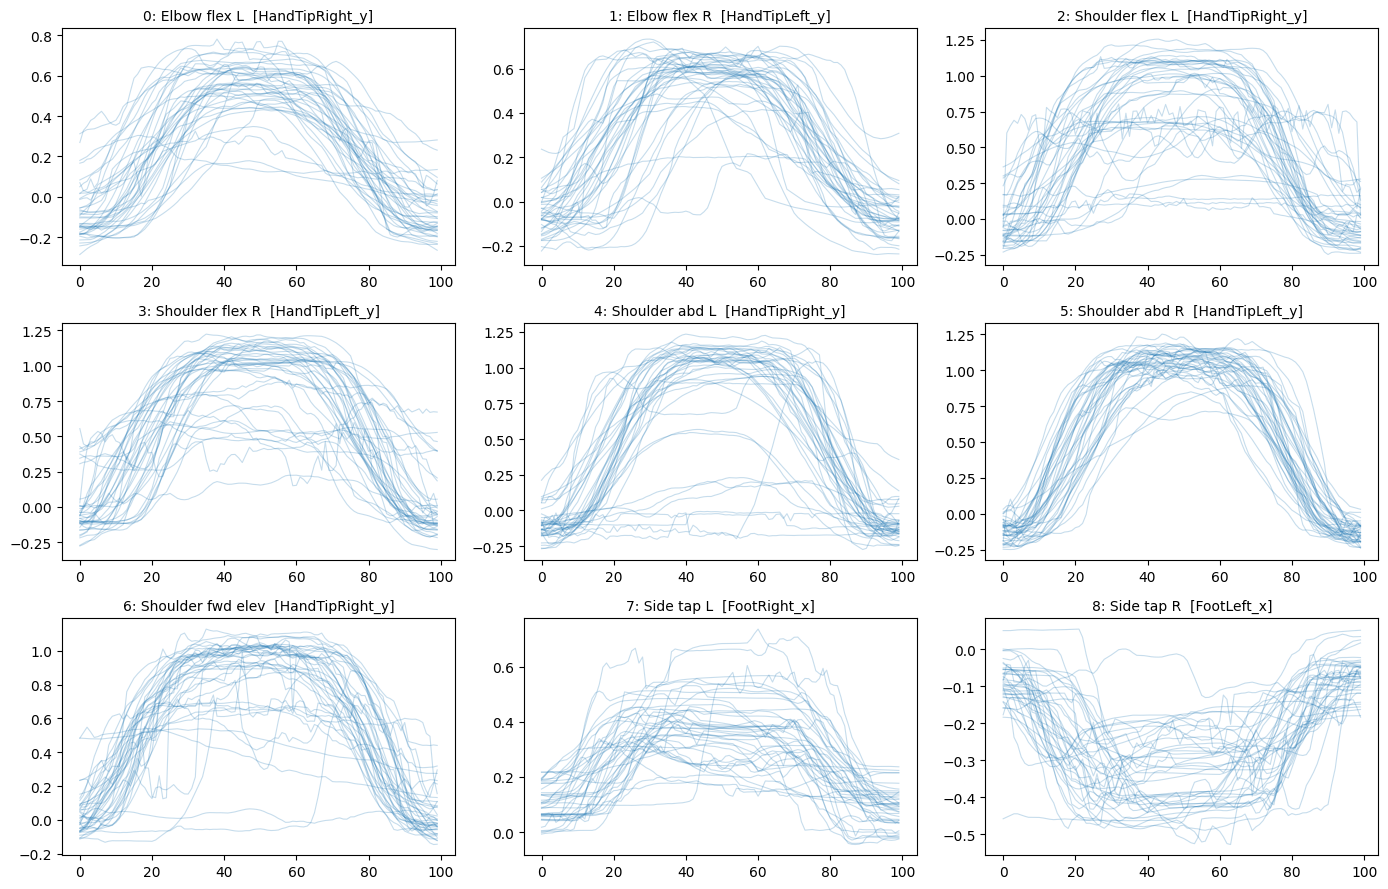

In [ ]:
def resample(x, n=N_FRAMES):
    t_old, t_new = np.linspace(0, 1, len(x)), np.linspace(0, 1, n)
    return np.stack([np.interp(t_new, t_old, x[:, j]) for j in range(x.shape[1])], axis=1)

def to_body_frame(x):
    # subtract the SpineBase (joint 0) in every frame: removes where the person stands, keeps body shape
    return x - np.tile(x[:, :3], 25)

fig, ax = plt.subplots(3, 3, figsize=(14, 9))
for g, a in enumerate(ax.ravel()):
    idx = np.where(meta.gesture == g)[0]
    R = np.stack([resample(to_body_frame(series[i])) for i in idx])          # reps x 100 x 75
    col = int(np.argmax((R.max(1) - R.min(1)).mean(0)))
    a.plot(R[:40, :, col].T, color="tab:blue", alpha=0.25, lw=0.8)
    a.set_title(f"{g}: {GESTURES[g]}  [{names[col]}]", fontsize=10)
plt.tight_layout(); plt.savefig("gesture_signals.png", dpi=150); plt.show()

## 5. Data processing: one repetition -> one row of numbers

1. **Body-relative:** subtract the SpineBase from every joint, so it does not matter where the person stands.
2. **Resample to 100 frames:** a 63-frame and a 4,000-frame repetition both become 100 frames.
3. **Joint angles:** elbow, shoulder, hip and knee angles (left and right) = 8 extra curves.
4. **Summarise each curve** with 7 numbers: min, max, range, mean, std, mean speed, mean acceleration.
5. **Duration:** the real length is lost by resampling, so add `log(1 + frames)` back.

Total: 75 x 7 + 8 x 7 + 1 = **582 features** per repetition. The 100 x 83 sequence (positions + angles) is kept too, for the CNN.

In [ ]:
STATS = ["min", "max", "range", "mean", "std", "speed", "accel"]
TRIPLES = {"elbow_L": (4, 5, 6), "elbow_R": (8, 9, 10), "shoulder_L": (12, 4, 5), "shoulder_R": (16, 8, 9),
           "hip_L": (4, 12, 13), "hip_R": (8, 16, 17), "knee_L": (12, 13, 14), "knee_R": (16, 17, 18)}

def joint_angles(x):
    J = x.reshape(len(x), -1, 3); out = []
    for a, b, c in TRIPLES.values():
        u, v = J[:, a] - J[:, b], J[:, c] - J[:, b]
        cos = (u * v).sum(1) / (np.linalg.norm(u, axis=1) * np.linalg.norm(v, axis=1) + 1e-9)
        out.append(np.degrees(np.arccos(np.clip(cos, -1, 1))))
    return np.stack(out, axis=1)

def stats(r):
    v, a = np.diff(r, axis=0), np.diff(r, n=2, axis=0)
    return [r.min(0), r.max(0), r.max(0) - r.min(0), r.mean(0), r.std(0), np.abs(v).mean(0), np.abs(a).mean(0)]

def features(x):
    return np.concatenate(stats(resample(to_body_frame(x))) + stats(resample(joint_angles(x))) + [[np.log1p(len(x))]])

def sequence(x):
    return np.concatenate([resample(to_body_frame(x)), resample(joint_angles(x))], 1).astype("float32")

X = np.nan_to_num(np.stack([features(s) for s in series]))
S = np.stack([sequence(s) for s in series])
D = np.log1p(meta.length.to_numpy()).astype("float32")[:, None]
y = meta.gesture.to_numpy()
groups = meta.subject.to_numpy()
print("Feature table:", X.shape, "| sequences:", S.shape)

Feature table: (2528, 582) | sequences: (2528, 100, 83)


### Mirror augmentation

Mirroring a repetition (flip x, swap every left joint with its right joint) turns "Shoulder flex **L**" into "Shoulder flex **R**" (and L/R of the other pairs; forward elevation stays itself).
That doubles the training data with correctly-labelled examples. The cell also runs a sanity check: a model trained on originals only should still recognise the mirrored repetitions.

In [ ]:
SWAP = list(range(25))
for a, b in [(4, 8), (5, 9), (6, 10), (7, 11), (12, 16), (13, 17), (14, 18), (15, 19), (21, 23), (22, 24)]:
    SWAP[a], SWAP[b] = b, a
FLIP = np.array([1, 0, 3, 2, 5, 4, 6, 8, 7])        # gesture index after mirroring

def mirror(x):
    J = x.reshape(len(x), 25, 3)[:, SWAP].copy()
    J[:, :, 0] *= -1
    return J.reshape(len(x), 75)

series_m = [mirror(s) for s in series]
X_m = np.nan_to_num(np.stack([features(s) for s in series_m]))
S_m = np.stack([sequence(s) for s in series_m])
y_m = FLIP[y]

folds = list(LeaveOneGroupOut().split(X, y, groups)) if N_FOLDS is None else list(GroupKFold(N_FOLDS).split(X, y, groups))
print("folds:", len(folds), "| train/test people never overlap")

folds: 5 | train/test people never overlap


## 6. Models

Every number below is measured on people the model has **never seen** (the folds keep each person entirely in train or entirely in test).
Four models, all trained on originals + mirrored copies. At test time each repetition is also looked at mirrored and the two predictions are averaged.

In [ ]:
models = {
    "LogReg": lambda: make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=2000)),
    "SVM": lambda: make_pipeline(StandardScaler(), SVC(C=10, probability=True, random_state=0)),
    "HistGB": lambda: HistGradientBoostingClassifier(max_iter=200, learning_rate=0.1, random_state=0),
}

# sanity check: train on originals, test on mirrored repetitions with flipped labels. Should be close to normal accuracy.
ok = np.zeros(len(y), int)
for tr, te in folds:
    ok[te] = models["LogReg"]().fit(X[tr], y[tr]).predict(X_m[te]) == y_m[te]
print(f"Sanity check (train original -> test mirrored): {ok.mean():.3f}\n")

P = {}      # out-of-fold probabilities for every model
for name, mk in models.items():
    p = np.zeros((len(y), 9))
    for tr, te in folds:
        m = mk().fit(np.vstack([X[tr], X_m[tr]]), np.r_[y[tr], y_m[tr]])
        p[te] = (m.predict_proba(X[te]) + m.predict_proba(X_m[te])[:, FLIP]) / 2
    P[name] = p
    print(f"{name:7s} accuracy {accuracy_score(y, p.argmax(1)):.3f}")

Sanity check (train original -> test mirrored): 0.881

LogReg  accuracy 0.884
SVM     accuracy 0.886
HistGB  accuracy 0.908


### 1D-CNN on the raw sequence

The network reads the 100 x 83 sequence (positions + angles) directly, looking for movement patterns over time. The repetition length is added after the convolutions.

In [ ]:
dev = "cuda" if torch.cuda.is_available() else "cpu"

class CNN(nn.Module):
    def __init__(s, channels, n_extra, n_out=9):
        super().__init__()
        blk = lambda i, o, k: nn.Sequential(nn.Conv1d(i, o, k, padding=k // 2), nn.BatchNorm1d(o), nn.ReLU())
        s.conv = nn.Sequential(blk(channels, 64, 5), blk(64, 128, 5), nn.MaxPool1d(2), blk(128, 128, 3))
        s.head = nn.Sequential(nn.Dropout(0.3), nn.Linear(256 + n_extra, 64), nn.ReLU(), nn.Linear(64, n_out))
    def forward(s, x, e):
        h = s.conv(x.transpose(1, 2))
        return s.head(torch.cat([h.mean(2), h.amax(2), e], 1))

def fit_predict(tr, te, labels, seq, extra, seed, epochs=30):
    """train on rows tr, return class probabilities for rows te. Scaling uses the training rows only."""
    mu, sd = seq[tr].mean((0, 1)), seq[tr].std((0, 1)) + 1e-6
    f = lambda i: (torch.tensor((seq[i] - mu) / sd).to(dev), torch.tensor(extra[i]).to(dev))
    (xtr, etr), (xte, ete) = f(tr), f(te)
    ytr = torch.tensor(labels[tr]).to(dev)
    torch.manual_seed(seed)
    net = CNN(seq.shape[2], extra.shape[1]).to(dev)
    opt = torch.optim.AdamW(net.parameters(), 1e-3, weight_decay=1e-2)
    loss_fn = nn.CrossEntropyLoss()
    for ep in range(epochs):
        net.train()
        for b in torch.randperm(len(tr)).split(64):
            if len(b) < 2: continue
            xb = xtr[b] + 0.05 * torch.randn_like(xtr[b])               # small noise = light augmentation
            loss = loss_fn(net(xb, etr[b]), ytr[b])
            opt.zero_grad(); loss.backward(); opt.step()
    net.eval()
    with torch.no_grad():
        return torch.softmax(net(xte, ete), 1).cpu().numpy()

N = len(y)
S2, D2, y2 = np.concatenate([S, S_m]), np.concatenate([D, D]), np.r_[y, y_m]      # originals + mirrored
p = np.zeros((N, 9))
for seed in range(N_SEEDS):
    for tr, te in folds:
        out = fit_predict(np.r_[tr, tr + N], np.r_[te, te + N], y2, S2, D2, seed)
        p[te] += (out[:len(te)] + out[len(te):][:, FLIP]) / 2 / N_SEEDS
    print("seed", seed, "done")
P["1D-CNN"] = p
print(f"1D-CNN  accuracy {accuracy_score(y, p.argmax(1)):.3f}")

seed 0 done
seed 1 done
seed 2 done
1D-CNN  accuracy 0.883


## 7. Results

,accuracy,balanced_acc
model,,
LogReg,0.884,0.889
SVM,0.886,0.888
HistGB,0.908,0.913
1D-CNN,0.883,0.889
ENSEMBLE,0.905,0.910


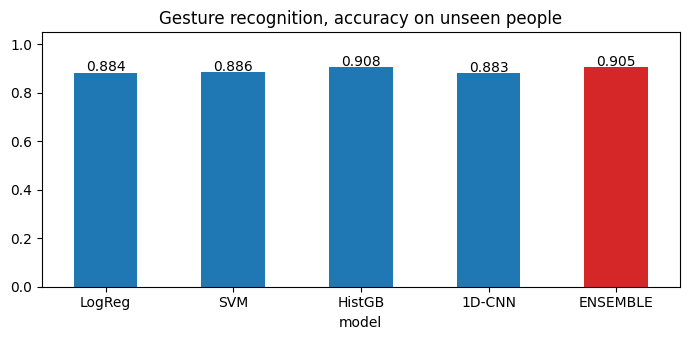

In [ ]:
P["ENSEMBLE"] = np.mean([P[k] for k in ["LogReg", "SVM", "HistGB", "1D-CNN"]], axis=0)     # simple average of the four
res = pd.DataFrame([[k, accuracy_score(y, p.argmax(1)), balanced_accuracy_score(y, p.argmax(1))] for k, p in P.items()],
                   columns=["model", "accuracy", "balanced_acc"]).set_index("model").round(3)
res.to_csv("results_gesture.csv")
display(res)

ax = res.accuracy.plot.bar(figsize=(7, 3.5), rot=0, color=["tab:blue"] * 4 + ["tab:red"])
ax.set_ylim(0, 1.05); ax.set_title("Gesture recognition, accuracy on unseen people")
for i, v in enumerate(res.accuracy): ax.text(i, v + 0.005, f"{v:.3f}", ha="center")
plt.tight_layout(); plt.savefig("gesture_models.png", dpi=150); plt.show()

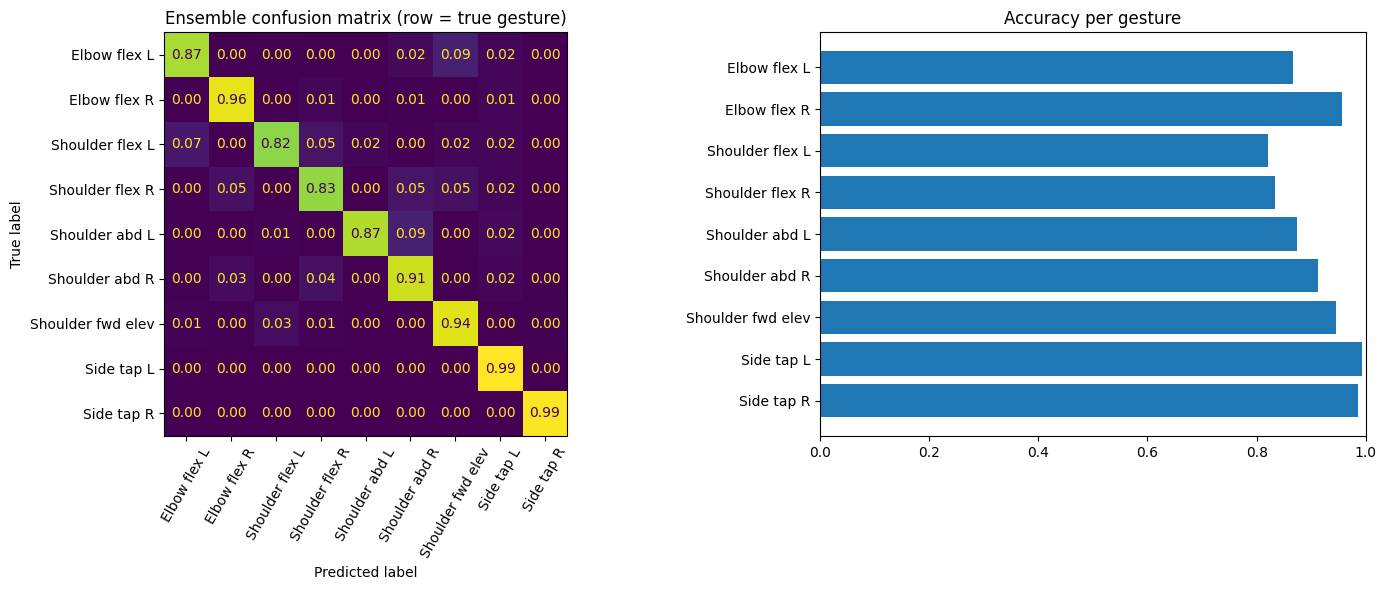

Most common mix-ups (true -> predicted):
  Shoulder flex L    -> Elbow flex L       25 times
  Shoulder abd L     -> Shoulder abd R     24 times
  Elbow flex L       -> Shoulder fwd elev  22 times
  Shoulder flex L    -> Shoulder flex R    20 times
  Shoulder flex R    -> Shoulder abd R     16 times
  Shoulder flex R    -> Elbow flex R       14 times


In [ ]:
pred = P["ENSEMBLE"].argmax(1)
fig, ax = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [1.4, 1]})
ConfusionMatrixDisplay.from_predictions(y, pred, display_labels=GESTURES, xticks_rotation=60, colorbar=False,
                                        ax=ax[0], normalize="true", values_format=".2f")
ax[0].set_title("Ensemble confusion matrix (row = true gesture)")
per = [(pred[y == g] == g).mean() for g in range(9)]
ax[1].barh(GESTURES[::-1], per[::-1], color="tab:blue"); ax[1].set_xlim(0, 1)
ax[1].set_title("Accuracy per gesture")
plt.tight_layout(); plt.savefig("gesture_confusion.png", dpi=150); plt.show()

cm = confusion_matrix(y, pred)
print("Most common mix-ups (true -> predicted):")
for i, j in sorted([(i, j) for i in range(9) for j in range(9) if i != j], key=lambda t: -cm[t])[:6]:
    print(f"  {GESTURES[i]:18s} -> {GESTURES[j]:18s} {cm[i, j]} times")

## 8. Notes for the write-up

* **Validation:** every score is on people not seen in training (grouped folds), so it measures generalisation to new users, not memorisation of a person. A random split would look better but would be misleading.
* **What helped:** joint-angle features, then mirror augmentation (more training data) and an ensemble of different model types.
* **Remaining errors:** mostly left/right pairs and similar arm exercises (see the mix-up list). Some patients move very differently from the average, which sets a ceiling.
* **Not IMU data:** this is camera-based skeleton data. A natural next step is to repeat the pipeline on your own dual-IMU recordings.
* Dataset: IntelliRehabDS, Zenodo 4610859, CC BY 4.0. Cite the dataset authors when you use it.